# Setup

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random as rn
import ast
import sys
sys.path.insert(1, r"/workspace/data\trojan\data engine")
import dataPrep as dp

# Inputs

In [3]:
path = r"/workspace/data\trojan\data bank\Cost of Living\Numbeo\Cost of Living Index_PATTERNS_DF.csv"

df   = pd.read_csv(path)
df   = df.drop("Unnamed: 0", axis = 1)

indexName  = path.split("\\")[-1].split(".")[0].split("_")[0]
country1   = rn.choice(list(set(df["Pattern Country"])))
country2   = rn.choice(list(set(df["Match Country"])))
patternLen = rn.choice(list(set(df["Pattern Length"]))) #rn.choice([8, 9, 10])
corrScore  = 0.9

# Crunching

In [4]:
c1df = dp.C1DF(df, country1, patternLen, corrScore)
c1df.head()

,Pattern Country,Match Country,Index,Pattern Values,Pattern Index,Match Values,Match Index,Rank,Score,Correlation Score,Euclidean Score,MAPE Score,DTW Score,CBD Score,Pattern Length
2835,Cambodia,Afghanistan,Cost of Living Index,"[53.64, 57.05, 47.29]","[2014, 2015, 2016]","[24.24, 26.33, 20.37]","[2020, 2021, 2022]",Platinum,0.0,1.0,50.33,0.55,50.33,0.51,3
2836,Cambodia,Albania,Cost of Living Index,"[57.05, 47.29, 46.77]","[2015, 2016, 2017]","[41.95, 33.81, 32.42]","[2015, 2016, 2017]",Platinum,0.0,1.0,24.81,0.29,24.81,0.51,3
2837,Cambodia,Algeria,Cost of Living Index,"[53.64, 57.05, 47.29]","[2014, 2015, 2016]","[40.64, 41.49, 39.11]","[2012, 2013, 2014]",Platinum,0.0,1.0,21.86,0.23,21.86,0.51,3
2838,Cambodia,Argentina,Cost of Living Index,"[57.05, 47.29, 46.77]","[2015, 2016, 2017]","[53.74, 33.09, 32.95]","[2018, 2019, 2020]",Platinum,0.0,1.0,20.09,0.22,20.09,0.51,3
2839,Cambodia,Armenia,Cost of Living Index,"[47.49, 47.91, 49.11]","[2020, 2021, 2022]","[31.68, 33.89, 40.8]","[2021, 2022, 2023]",Platinum,0.0,1.0,22.71,0.26,22.71,0.51,3


In [5]:
# Execute this first code block if the C1 dataframe has the passed pattern length `patternLen`
# Then transform it to a vizzable dataframe `dfViz`
if not isinstance(c1df, dict):
    # Pattern Index options
    pattIndex = rn.choice(list(set(c1df["Pattern Index"])))
    print("Pattern Indexes")
    print(list(set(c1df["Pattern Index"])))
    print("Choice:", pattIndex)

    c1df  = c1df[c1df["Pattern Index"] == pattIndex]
    dfViz = dp.patternVsMatchesDF(c1df, country1, patternLen)
else:
    print("Selected pattern length (", patternLen, ") does not apply to selected country (", country1, "). ")

Pattern Indexes
['[2013, 2014, 2015]', '[2014, 2015, 2016]', '[2018, 2019, 2020]', '[2016, 2017, 2018]', '[2021, 2022, 2023]', '[2020, 2021, 2022]', '[2017, 2018, 2019]', '[2015, 2016, 2017]', '[2019, 2020, 2021]']
Choice: [2021, 2022, 2023]


# Viz

/workspace\AppData\Local\Temp\ipykernel_16912\2619908069.py:1: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use("seaborn-darkgrid")


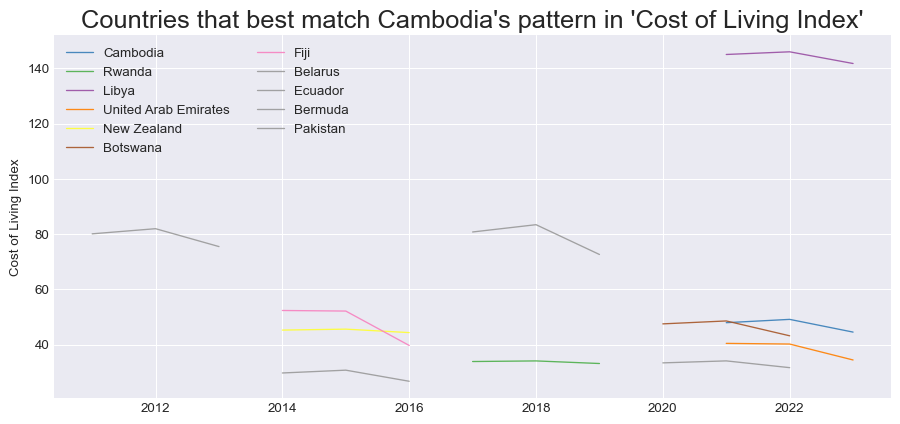

In [6]:
plt.style.use("seaborn-darkgrid")
my_dpi = 96
plt.figure(figsize = (1080 / my_dpi, 480 / my_dpi), dpi = my_dpi)
palette = plt.get_cmap("Set1")
 
num = 0
for column in dfViz.drop("Years", axis = 1):
    num += 1
    plt.plot(dfViz["Years"], dfViz[column], marker = "", color = palette(num), linewidth = 1, alpha = 0.9, label = column)

plt.legend(loc = 2, ncol = 2)
 
plt.title("Countries that best match " + country1 + "'s pattern in '" + indexName + "'", loc = "center", fontsize = 19, fontweight = 0)
#plt.xlabel("Time")
plt.ylabel(indexName) # <<<<<<<<<<

plt.show()